First five rows:
   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647             

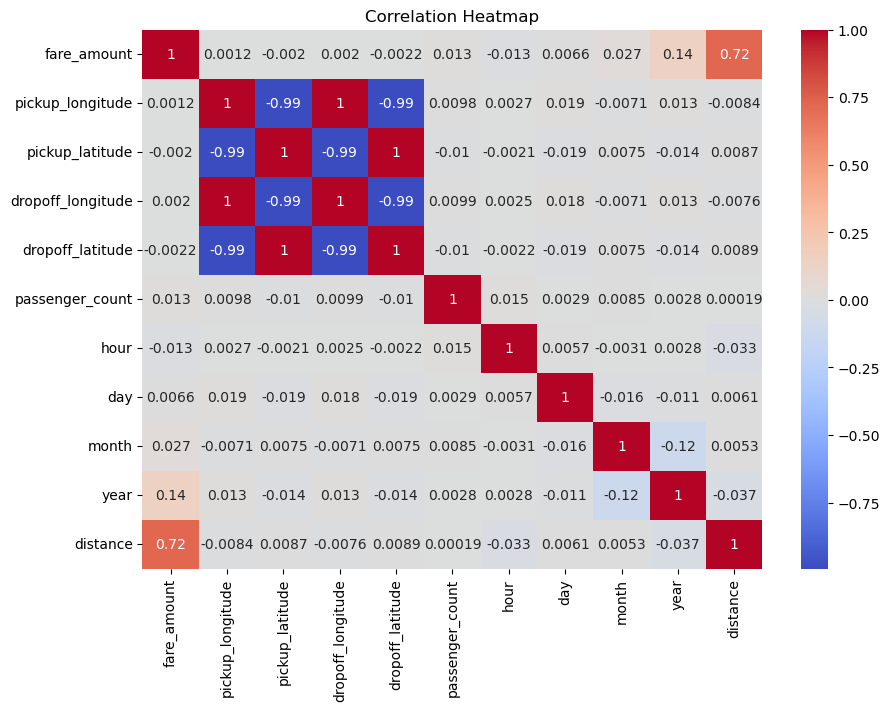


Model Comparison:
               Model       MAE       MSE      RMSE  R2 Score
0  Linear Regression  1.796305  6.524028  2.554218  0.617221
1   Ridge Regression  1.794628  6.533634  2.556097  0.616657
2   Lasso Regression  1.839841  6.743757  2.596875  0.604329


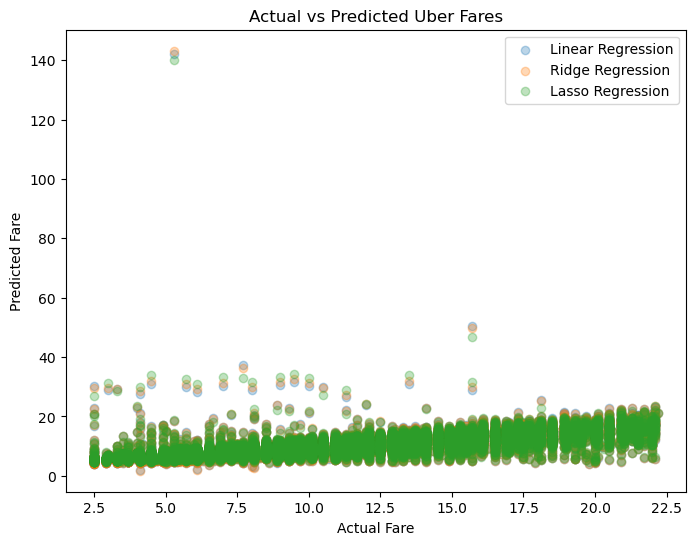

In [1]:

# 1. Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 2. Load the dataset
df = pd.read_csv("uber.csv")

print("First five rows:")
print(df.head())

# 3. Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Replace missing numerical values with median
df = df.fillna(df.median(numeric_only=True))

# 4. Display data types
print("\nData types:")
print(df.dtypes)

# Convert pickup_datetime into datetime format
df["pickup_datetime"] = pd.to_datetime(
    df["pickup_datetime"], errors="coerce"
)

# Remove rows with invalid datetime values
df = df.dropna(subset=["pickup_datetime"])

# 5. Extract useful date and time features
df["hour"] = df["pickup_datetime"].dt.hour
df["day"] = df["pickup_datetime"].dt.day
df["month"] = df["pickup_datetime"].dt.month
df["year"] = df["pickup_datetime"].dt.year

# 6. Remove unnecessary columns
df = df.drop(
    columns=["key", "Unnamed: 0", "pickup_datetime"],
    errors="ignore"
)

# 7. Remove invalid values
df = df[
    (df["fare_amount"] > 0) &
    (df["passenger_count"] > 0) &
    (df["passenger_count"] <= 6) &
    (df["pickup_latitude"].between(-90, 90)) &
    (df["dropoff_latitude"].between(-90, 90)) &
    (df["pickup_longitude"].between(-180, 180)) &
    (df["dropoff_longitude"].between(-180, 180))
]

# 8. Calculate distance using Haversine formula
def calculate_distance(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2 +
        np.cos(lat1) * np.cos(lat2) *
        np.sin(dlon / 2) ** 2
    )

    return 6371 * 2 * np.arcsin(np.sqrt(a))

df["distance"] = calculate_distance(
    df["pickup_latitude"],
    df["pickup_longitude"],
    df["dropoff_latitude"],
    df["dropoff_longitude"]
)

# Remove zero or unusually large distances
df = df[
    (df["distance"] > 0) &
    (df["distance"] < 100)
]

# 9. Identify outliers using IQR method
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df["fare_amount"] < lower) |
    (df["fare_amount"] > upper)
]

print("\nNumber of fare outliers:", len(outliers))

# Remove fare outliers
df = df[
    (df["fare_amount"] >= lower) &
    (df["fare_amount"] <= upper)
]

# 10. Check correlation
plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

# 11. Separate independent and dependent variables
X = df.drop("fare_amount", axis=1)
y = df["fare_amount"]

# 12. Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 13. Standardize the features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 14. Create regression models
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.1)
}

# 15. Train, predict and evaluate models
results = []

for name, model in models.items():

    # Train the model
    model.fit(X_train, y_train)

    # Predict test data
    y_pred = model.predict(X_test)

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append([name, mae, mse, rmse, r2])

# 16. Display comparison
result_df = pd.DataFrame(
    results,
    columns=["Model", "MAE", "MSE", "RMSE", "R2 Score"]
)

print("\nModel Comparison:")
print(result_df)

# 17. Visualize actual vs predicted values
plt.figure(figsize=(8, 6))

for name, model in models.items():
    predictions = model.predict(X_test)
    plt.scatter(y_test, predictions, alpha=0.3, label=name)

plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.title("Actual vs Predicted Uber Fares")
plt.legend()
plt.show()


In [ ]:
!pip install numpy pandas matplotlib seaborn scikit-learn